<b><font color='aquamarine' size="6"> Data Preprocessing and Visualization

<b><font size="6" color="aquamarine">City Hospital – Data Preprocessing &
Exploratory Analysis</i></font></b><a class="anchor"></a><a id="toc"></a><br>

### Group 16 - Team Members

| Name | Student Number |
|---|---|
| João Umbelino | 20251309 |
| Mariana Monteiri | 20251290 |
| Martim Violante | 20251310 |
| Rafael Portela | 20251361 |


---
## <font color='#BFD72F'>Table of Contents</font> <a class="anchor" id='toc'></a>
- [1. Part A - Data Understanding & Cleaning](#1)
  - [1.1 Loading and Importing the Data](#1_1)
    - [1.1.1 Initial Understanding of the Dataset](#1_1_1)
  - [1.2 Handling Duplicate Records](#1_2)
    - [1.2.1 Identifying Duplicate Rows](#1_2_1)
    - [1.2.2 Removing Duplicate Records](#1_2_2)
    - [1.2.3 Justifying the Cleaning Decisions](#1_2_3)
  - [1.3 Identify and Handle Missing Values](#1_3)
    - [1.3.1 Identifying Missing Values Across Variables](#1_3_1)
    - [1.3.2 Handling Missing Values](#1_3_2)
  - [1.4 Handling Inconsistent Data](#1_4)
      - [1.4.1 Identifying Inconsistent Data](#1_4_1)
        - [1.4.1.1 Syntax, Data Types & Format Errors (Dates, Negative Values)](#1_4_1_1)
        - [1.4.1.2 Invalid Categorical Labels & Out-of-Scale Scores](#1_4_1_2)
        - [1.4.1.3 Demographics & Logical Contradictions (Insurance, Attributes)](#1_4_1_3)
        - [1.4.1.4 Cross-Visit & Longitudinal Inconsistencies](#1_4_1_4)
      - [1.4.2 Correcting and Standardizing Inconsistent Data](#1_4_2)
        - [1.4.2.1 Type Casting & Format Alignment](#1_4_2_1)
        - [1.4.2.2 Category Mapping & Text Standardization](#1_4_2_2)
        - [1.4.2.3 Conflict Resolution for Static & Longitudinal Patient Data](#1_4_2_3)
        - [1.4.2.4 Domain Rule Enforcement & Out-of-Bounds Remediation](#1_4_2_4)
  - [1.5 Identifying and Handling Outliers](#1_5)
    - [1.5.1 Detecting Outliers in Numerical Variables](#1_5_1)
    - [1.5.2 Visualizing Potential Outliers](#1_5_2)
    - [1.5.3 Deciding How to Handle Outliers](#1_5_3)

- [2. Part B - Feature Engineering & ABT Construction](#2)
  - [2.1 Patient-Level ABT Construction](#2_1)
    - [2.1.1 Static Attributes](#2_1_1)
    - [2.1.2 Visit Behaviour Features](#2_1_2)
    - [2.1.3 Financial Features](#2_1_3)
    - [2.1.4 Satisfaction Features](#2_1_4)
    - [2.1.5 Recency and Activity Features](#2_1_5)
  - [2.2 Data Dictionary](#2_2)
  - [2.3 Exporting the ABT](#2_3)

- [3. Part C - Exploratory Visualization & Insights](#3)
  - [3.1 Patient Demographics](#3_1)
    - [3.1.1 Age Distribution](#3_1_1)
    - [3.1.2 Gender Distribution](#3_1_2)
    - [3.1.3 Income Distribution](#3_1_3)
  - [3.2 Department and Service Usage](#3_2)
    - [3.2.1 Consultations by Department](#3_2_1)
    - [3.2.2 Consultations Over Time](#3_2_2)
    - [3.2.3 Department Usage by Gender or Age Group](#3_2_3)
  - [3.3 Patient Satisfaction](#3_3)
    - [3.3.1 Satisfaction by Department](#3_3_1)
    - [3.3.2 Satisfaction by Patient Segment](#3_3_2)
  - [3.4 Additional Visualizations](#3_4)
  - [3.5 Management Questions and Key Insights](#3_5)

### <font color='turquoise' size='6'>1. Part A – Data Understanding & Cleaning </font> <a class="anchor" id="1"></a>
  [Back to TOC](#toc)

Every issue is detected in code, a decision is taken (**correct / impute / flag / remove**) and explained in the text right below it. Patients are never removed: every problem is repaired or flagged at visit level.


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

## <font color='turquoise'>1.1 Loading and Importing the Data

In [31]:
data = pd.read_excel('Project Data.xlsx')
df = data.copy()

## <font color='turquoise'>1.1.1 Initial Understanding of the Dataset

In [32]:
df.head()

,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
0,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-02-22,Endocrinology,110,2,38839.0,293.014042,0.0
1,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-01-21,Emergency,76,4,52219.0,287.208982,0.0
2,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-06-13,Neurology,17,5,41491.0,241.254507,0.0
3,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-24,Emergency,15,3,34944.0,221.177483,0.0
4,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-19,Neurology,99,1,39248.0,219.743794,0.0


In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10008 entries, 0 to 10007
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Patient ID                 10008 non-null  int64         
 1   Age                        9952 non-null   float64       
 2   Gender                     10008 non-null  str           
 3   City of Residence          10008 non-null  str           
 4   Profession                 10008 non-null  str           
 5   Insurance Provider         8098 non-null   str           
 6   Family History             8015 non-null   str           
 7   Education Level            9979 non-null   str           
 8   Marital Status             10008 non-null  str           
 9   Visit Date                 10008 non-null  datetime64[us]
 10  Department                 10008 non-null  str           
 11  Consultation Duration      10008 non-null  int64         
 12  Satisfaction Le

In [34]:
print("Dataset dimensions:", df.shape)
print()

print("Data types:")
print(df.dtypes)

print()
print("Number of unique patients:", df["Patient ID"].nunique())

Dataset dimensions: (10008, 16)

Data types:
Patient ID                            int64
Age                                 float64
Gender                                  str
City of Residence                       str
Profession                              str
Insurance Provider                      str
Family History                          str
Education Level                         str
Marital Status                          str
Visit Date                   datetime64[us]
Department                              str
Consultation Duration                 int64
Satisfaction Level                    int64
Approximate Annual Income           float64
Consultation Price                  float64
Insurance Coverage                  float64
dtype: object

Number of unique patients: 500


In [35]:
print("\nNumerical summary:")
display(df.describe().T.round(2))



Numerical summary:


,count,mean,min,25%,50%,75%,max,std
Patient ID,10008.0,1251.580735,1000.0,1127.0,1252.0,1375.0,1499.0,144.576421
Age,9952.0,50.635651,0.0,23.0,52.0,75.0,195.0,31.185608
Visit Date,10008,2024-03-31 14:53:14.244604,2024-01-01 00:00:00,2024-02-15 00:00:00,2024-03-31 00:00:00,2024-05-16 00:00:00,2024-06-30 00:00:00,NaN
Consultation Duration,10008.0,67.807654,15.0,41.0,68.0,94.0,600.0,32.447143
Satisfaction Level,10008.0,3.202338,1.0,2.0,3.0,5.0,6.0,1.565507
Approximate Annual Income,9854.0,43402.761315,0.0,31157.75,40876.5,50721.75,11970900.0,268142.006041
Consultation Price,10008.0,187.263022,50.036762,111.316562,159.531115,199.820999,39999.222018,862.86555
Insurance Coverage,9958.0,115.429366,0.0,59.692518,115.938998,165.437958,421.887836,79.337759


## <font color='turquoise'>1.2 Checking Duplicate Records

## <font color='turquoise'>1.2.1 Identifying Duplicate Rows

In [36]:
# (a) exact duplicates: all 16 fields identical
dup_exact = df.duplicated()
print("Exact duplicate rows (all 16 fields identical):", int(dup_exact.sum()))
display(df[df.duplicated(keep=False)].sort_values(["Patient ID", "Visit Date", "Department"]))

# (b) same patient + date + department, but at least one other field differs
key = ["Patient ID", "Visit Date", "Department"]
after_exact = df[~dup_exact]
print(f"\nRows sharing patient + date + department after removing exact duplicates: {int(after_exact.duplicated(key, keep=False).sum())}")
display(after_exact[after_exact.duplicated(key, keep=False)].sort_values(key).head(6))





# Check for duplicate rows in the dataset
duplicate_rows = df[df.duplicated()]

# Display the number of duplicate rows
print(f"Number of duplicate rows: {duplicate_rows.shape[0]}")

# Optionally, you can also view the duplicate rows
print("\nDuplicate Rows:")
duplicate_rows

Exact duplicate rows (all 16 fields identical): 8


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
1769,1011,11.0,Female,London,Student,NaN,NaN,Middle school/junior high,Single,2024-04-12,Psychiatry,101,1,0.0,133.415959,0.000000
1770,1011,11.0,Female,London,Student,NaN,NaN,Middle school/junior high,Single,2024-04-12,Psychiatry,101,1,0.0,133.415959,0.000000
983,1217,78.0,Other,London,Retired,NaN,Heart Disease,Undergraduate,Divorced,2024-05-03,Rheumatology,109,4,52131.0,164.423323,0.000000
984,1217,78.0,Other,London,Retired,NaN,Heart Disease,Undergraduate,Divorced,2024-05-03,Rheumatology,109,4,52131.0,164.423323,0.000000
2863,1253,38.0,Other,Manchester,Engineer,Provider A,Hypertension,Master,Married,2024-03-25,Emergency,70,2,32726.0,355.401954,284.321563
2864,1253,38.0,Other,Manchester,Engineer,Provider A,Hypertension,Master,Married,2024-03-25,Emergency,70,2,32726.0,355.401954,284.321563
2711,1287,68.0,Male,Birmingham,Retired,Provider A,Cancer,Undergraduate,Widowed,2024-06-16,Rheumatology,99,4,37375.0,141.686817,113.349454
2712,1287,68.0,Male,Birmingham,Retired,Provider A,Cancer,Undergraduate,Widowed,2024-06-16,Rheumatology,99,4,37375.0,141.686817,113.349454
8714,1306,91.0,Female,London,Retired,Provider D,Hypertension,Master,Widowed,2024-03-11,Orthopedics,32,1,33036.0,221.795387,221.795387
8715,1306,91.0,Female,London,Retired,Provider D,Hypertension,Master,Widowed,2024-03-11,Orthopedics,32,1,33036.0,221.795387,221.795387



Rows sharing patient + date + department after removing exact duplicates: 114


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
7706,1002,10.0,Female,Liverpool,Student,Provider C,Cancer,Elementary school,Single,2024-05-01,Neurology,18,2,0.0,253.175667,177.222967
7707,1002,10.0,Female,Liverpool,Student,Provider C,Cancer,Elementary school,Single,2024-05-01,Neurology,109,3,0.0,251.804387,176.263071
9974,1014,71.0,Male,Birmingham,Retired,NaN,Hypertension,Undergraduate,Divorced,2024-01-29,Endocrinology,61,5,46392.0,170.384828,153.346345
9977,1014,71.0,Male,Birmingham,Retired,NaN,Hypertension,Undergraduate,Divorced,2024-01-29,Endocrinology,115,3,33926.0,158.981191,143.083072
5765,1015,1.0,Female,Manchester,Student,Provider B,Heart Disease,Pre-school,Single,2024-04-02,Psychiatry,109,3,0.0,102.272316,92.045085
9958,1015,1.0,Female,Manchester,Student,NaN,Heart Disease,Pre-school,Single,2024-04-02,Psychiatry,98,2,0.0,163.672006,147.304806


Number of duplicate rows: 8

Duplicate Rows:


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
510,1330,60.0,Female,Manchester,Artist,NaN,Diabetes,Undergraduate,Married,2024-06-27,Orthopedics,118,1,48263.0,172.566249,NaN
984,1217,78.0,Other,London,Retired,NaN,Heart Disease,Undergraduate,Divorced,2024-05-03,Rheumatology,109,4,52131.0,164.423323,0.000000
1770,1011,11.0,Female,London,Student,NaN,NaN,Middle school/junior high,Single,2024-04-12,Psychiatry,101,1,0.0,133.415959,0.000000
2345,1363,18.0,Male,Glasgow,Student,Provider A,NaN,High school,Single,2024-04-01,Allergology,61,4,0.0,126.757994,101.406395
2712,1287,68.0,Male,Birmingham,Retired,Provider A,Cancer,Undergraduate,Widowed,2024-06-16,Rheumatology,99,4,37375.0,141.686817,113.349454
2864,1253,38.0,Other,Manchester,Engineer,Provider A,Hypertension,Master,Married,2024-03-25,Emergency,70,2,32726.0,355.401954,284.321563
8031,1443,16.0,Male,Belfast,Student,Provider D,NaN,High school,Single,2024-05-31,Psychiatry,45,5,0.0,113.077347,113.077347
8715,1306,91.0,Female,London,Retired,Provider D,Hypertension,Master,Widowed,2024-03-11,Orthopedics,32,1,33036.0,221.795387,221.795387


## <font color='turquoise'>1.2.2 Removing Duplicate Records

In [37]:
# (a) exact duplicates -> remove (keep first)
df = df.drop_duplicates().copy()

# (b) same patient/date/department but different values -> keep and flag
df["flag_same_day_same_dept"] = df.duplicated(key, keep=False)

print(f"Rows after removing exact duplicates: {len(df):,}  |  patients: {df['Patient ID'].nunique()}")
print(f"Fewest visits left for any patient: {df.groupby('Patient ID').size().min()}")
print(f"Rows flagged as same patient/date/department: {int(df['flag_same_day_same_dept'].sum())}")

Rows after removing exact duplicates: 10,000  |  patients: 500
Fewest visits left for any patient: 9
Rows flagged as same patient/date/department: 114


## <font color='turquoise'> 1.2.3 Justifying the Cleaning Decisions

| Finding | Decision | Why |
|---|---|---|
| 8 rows identical in all 16 fields | **Remove** (keep first) | The price is a continuous number, so two visits matching to many decimals are a double-entry, not two consultations. |
| 114 rows share patient + date + department but differ in duration / rating / price | **Keep and flag** | The values differ, so they can be separate consultations on the same day. Deleting them would remove real activity; the flag lets the next team exclude them if needed. |
| Patients lost | **None** | Every patient keeps at least 9 visits after de-duplication. |

## <font color='turquoise'>1.3 Identify and Handle Missing Values
[Back to TOC](#toc)

## <font color='turquoise'>1.3.1 Identifying Missing Values Across Variables

In [38]:
df.info()

<class 'pandas.DataFrame'>
Index: 10000 entries, 0 to 10007
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Patient ID                 10000 non-null  int64         
 1   Age                        9944 non-null   float64       
 2   Gender                     10000 non-null  str           
 3   City of Residence          10000 non-null  str           
 4   Profession                 10000 non-null  str           
 5   Insurance Provider         8093 non-null   str           
 6   Family History             8010 non-null   str           
 7   Education Level            9971 non-null   str           
 8   Marital Status             10000 non-null  str           
 9   Visit Date                 10000 non-null  datetime64[us]
 10  Department                 10000 non-null  str           
 11  Consultation Duration      10000 non-null  int64         
 12  Satisfaction Level  

In [39]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage (%)': missing_percent.round(2)
})

missing_summary[missing_summary['Missing Values'] > 0]

,Missing Values,Percentage (%)
Age,56,0.56
Insurance Provider,1907,19.07
Family History,1990,19.90
Education Level,29,0.29
Approximate Annual Income,154,1.54
Insurance Coverage,49,0.49


### 1.3.2 Analysing Missing Data Patterns

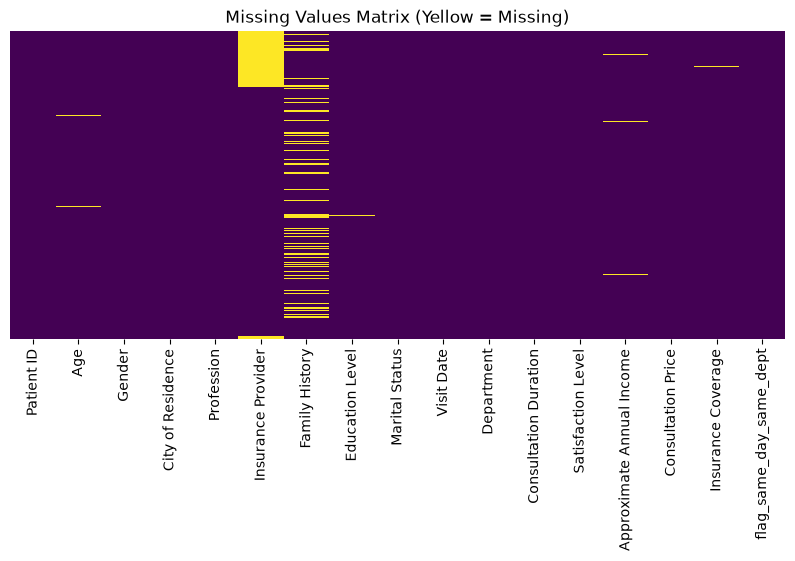

In [40]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Values Matrix (Yellow = Missing)')
plt.show()

The missing value heatmap above illustrates the distribution and structure of missingness across the dataset:

* **Primary Contributors to Missingness:** Missing data is overwhelmingly concentrated in two categorical features: `Insurance Provider` (1,910 missing values) and `Family History` (1,993 missing values).
* **Patient-Level Systematic Patterns:** The continuous vertical block observed in `Insurance Provider` indicates systematic missingness at the patient level, where specific patients lack insurance provider information across all recorded consultations.
* **Random Sporadic Missingness:** In contrast, `Family History` exhibits a scattered pattern across rows, representing sporadic non-reporting during individual clinical visits rather than a structural omission.
* **Low-Volume Omissions:** Demographic and financial features (`Age`, `Education Level`, `Approximate Annual Income`, and `Insurance Coverage`) display isolated, minimal gaps, confirming that missing values in these fields represent a minor fraction of the total observations.

## <font color='turquoise'>1.3.2 Handling Missing Values

In [41]:
df_imputed = df.copy()

for col in ['Age', 'Education Level']:
    df_imputed[col] = df_imputed.groupby('Patient ID')[col].ffill().bfill()

df_imputed['Insurance Provider'] = df_imputed.groupby('Patient ID')['Insurance Provider'].ffill().bfill()

rate_by_provider = {0.0: 'None', 0.8: 'Provider A', 0.9: 'Provider B', 0.7: 'Provider C', 1.0: 'Provider D'}
ratio = (df_imputed['Insurance Coverage'] / df_imputed['Consultation Price']).round(1)

df_imputed['Insurance Provider'] = df_imputed['Insurance Provider'].fillna(ratio.map(rate_by_provider))

provider_rates = {'None': 0.0, 'Provider A': 0.8, 'Provider B': 0.9, 'Provider C': 0.7, 'Provider D': 1.0}
expected_rate = df_imputed['Insurance Provider'].map(provider_rates)

df_imputed['Insurance Coverage'] = df_imputed['Insurance Coverage'].fillna(expected_rate * df_imputed['Consultation Price'])

income_median = df_imputed.groupby('Patient ID')['Approximate Annual Income'].transform('median')

df_imputed['Approximate Annual Income'] = df_imputed['Approximate Annual Income'].fillna(income_median)

df_imputed['Family History'] = df_imputed['Family History'].fillna('Unknown')

print("Missing values after imputation:")
print(df_imputed.isnull().sum())

Missing values after imputation:
Patient ID                   0
Age                          0
Gender                       0
City of Residence            0
Profession                   0
Insurance Provider           0
Family History               0
Education Level              0
Marital Status               0
Visit Date                   0
Department                   0
Consultation Duration        0
Satisfaction Level           0
Approximate Annual Income    0
Consultation Price           0
Insurance Coverage           0
flag_same_day_same_dept      0
dtype: int64


To handle the missing data identified across the dataset, a multi-tiered imputation strategy was implemented based on domain rules, patient-level consistency, and mathematical relationships between variables:

* **Demographic Variables (`Age` & `Education Level`):** 
  Since age and formal education level are invariant characteristics for a given individual across the short observational timeframe, missing values were propagated directly from each patient's other recorded clinical visits (`ffill().bfill()` grouped by `Patient ID`). This restores true historical values without introducing synthetic noise.

* **Insurance Provider (`Insurance Provider`):** 
  Imputation was carried out in two sequential steps:
  1. *Patient-Level Propagation:* Missing provider values were first filled using known insurance records from the same patient's other visits.
  2. *Deterministic Coverage Ratio Mapping:* For patients with no provider recorded across all visits, the provider was reverse-engineered using the exact ratio between insurance coverage and consultation price ($\text{Ratio} = \frac{\text{Insurance Coverage}}{\text{Consultation Price}}$). Since each provider operates on a fixed coverage rate ($0.0 \rightarrow \text{None}$, $0.7 \rightarrow \text{Provider C}$, $0.8 \rightarrow \text{Provider A}$, $0.9 \rightarrow \text{Provider B}$, $1.0 \rightarrow \text{Provider D}$), the underlying provider was mapped deterministically.

* **Insurance Coverage (`Insurance Coverage`):** 
  Missing values were imputed deterministically by applying the corresponding insurance provider's coverage rate to the total consultation cost ($\text{Coverage} = \text{Provider Rate} \times \text{Consultation Price}$). This preserves exact mathematical consistency across financial fields.

* **Approximate Annual Income (`Approximate Annual Income`):** 
  Because annual income exhibits minor reporting variations across visits, missing entries were imputed using the median income calculated per patient (`transform('median')`). This approach reduces distortion from single-visit anomalies while preserving zero-income entries for young or unemployed patients.

* **Family History (`Family History`):** 
  Given the sporadic nature of missing medical history entries and the categorical structure of the feature, remaining missing values were explicitly imputed as `'Unknown'`. This avoids fabricating clinical background while retaining all patient records for subsequent analytical steps.

**Imputation decisions**

| Variable | Strategy | Why |
|---|---|---|
| Age, Education Level | Fill with the patient's own value from other visits | Static per patient and always available; no information is invented. |
| Insurance Provider | Infer from `coverage / price`, fall back to the patient's other visits | Each provider pays a fixed share (A 80%, B 90%, C 70%, D 100%, None 0%), so the ratio is a fingerprint of the provider. |
| Approximate Annual Income | Leave missing per visit; use the patient **median** in the ABT (2.1.1) | Income varies a little from visit to visit; a median is robust and every patient has at least one value. |
| Insurance Coverage | Recompute `rate x price` in 1.4.9 | Deterministic business rule; needs a validated price first. |

The ratio table above shows the evidence: for every provider the minimum equals the median rate (A 0.8, B 0.9, C 0.7, D 1.0, None 0); the few larger maxima are the 6 off-rule rows treated in 1.4.9.

Group-mean imputation was rejected: it would blur genuine differences between patients.

## <font color='turquoise'>1.4 Handle Inconsistent Data

[Back to TOC](#toc)



<a id="1_4_1"></a>

## <font color='turquoise'>1.4.1 Identifying Inconsistent Data

<a id="1_4_2"></a>

## <font color='turquoise'>1.4.2 Correcting and Standardizing Inconsistent Data

<a id="1_5"></a>

## <font color='turquoise'>1.5 Identifying and Handling Outliers
[Back to TOC](#toc)

<a id="1_5_1"></a>

## <font color='turquoise'>1.5.1 Detecting Outliers in Numerical Variables

In [42]:
#Two complementary tests: the statistical **IQR rule** (1.5 x IQR) and **domain rules** (what is physically/commercially possible).

<a id="1_5_2"></a>

## <font color='turquoise'> 1.5.2 Visualizing Potential Outliers

<a id="1_5_3"></a>

## <font color='turquoise'> 1.5.3 Deciding How to Handle Outliers

<a id="2"></a>

## <font color='turquoise'> 2. Part B - Feature Engineering & ABT Construction

[Back to TOC](#toc)


<a id="2_1"></a>

## <font color='turquoise'> 2.1 Patient-Level ABT Construction

In [43]:
g = df.groupby("Patient ID", observed=True)
dept_s = df["Department"].astype(str)                  # plain strings for the department logic
abt = pd.DataFrame(index=g.size().index)
abt.index.name = "patient_id"

<a id="2_1_1"></a>

## <font color='turquoise'> 2.1.1 Static Attributes

In [44]:
abt["age"] = g["Age"].first().astype(int)
abt["age_group"] = pd.cut(abt["age"], AGE_BINS, labels=AGE_LAB).astype(str)
abt["gender"] = g["Gender"].first().astype(str)
abt["city"] = g["City of Residence"].first().astype(str)
abt["profession"] = g["Profession"].first().astype(str)
abt["education_level"] = g["Education Level"].first().astype(str)
abt["education_ordinal"] = abt["education_level"].map({k: i for i, k in enumerate(EDU)})
abt["marital_status"] = g["Marital Status"].first().astype(str)
abt["family_history"] = g["Family History"].first().astype(str)
abt["has_family_history"] = (abt["family_history"] != "None").astype(int)
abt["insurance_provider"] = g["Insurance Provider"].agg(lambda s: s.mode().iloc[0]).astype(str)
abt["has_insurance"] = (abt["insurance_provider"] != "None").astype(int)
abt["insurance_coverage_rate"] = abt["insurance_provider"].map(RATE)
abt["annual_income"] = g["Approximate Annual Income"].median().round(0)
abt["income_std"] = g["Approximate Annual Income"].std().round(0)
assert abt["annual_income"].notna().all()
display(abt.head(3))

NameError: name 'AGE_BINS' is not defined

<a id="2_1_2"></a>

## <font color='turquoise'> 2.1.2 Visit Behaviour Features

In [ ]:
gd = dept_s.groupby(df["Patient ID"])
abt["n_visits"] = g.size()
abt["n_distinct_departments"] = gd.nunique()
abt["top_department"] = gd.agg(lambda s: s.value_counts(sort=False).idxmax())   # ties: first department seen
abt["top_department_share"] = (gd.agg(lambda s: s.value_counts(sort=False).max()) / abt["n_visits"]).round(4)
abt["avg_duration_min"] = g["Consultation Duration"].mean().round(2)
abt["std_duration_min"] = g["Consultation Duration"].std().round(2)
abt["total_duration_min"] = g["Consultation Duration"].sum()
abt["n_emergency_visits"] = gd.agg(lambda s: (s == "Emergency").sum())
abt["share_emergency"] = (abt["n_emergency_visits"] / abt["n_visits"]).round(4)
dept_counts = pd.crosstab(df["Patient ID"], dept_s)
dept_counts.columns = ["visits_" + c.lower().replace(" ", "_") for c in dept_counts.columns]
abt = abt.join(dept_counts)
display(abt[["n_visits", "n_distinct_departments", "top_department", "top_department_share", "avg_duration_min"]].head(3))

<a id="2_1_3"></a>

## <font color='turquoise'> 2.1.3 Financial Features

In [ ]:
abt["total_price"] = g["Consultation Price"].sum().round(2)
abt["avg_price"] = g["Consultation Price"].mean().round(2)
abt["total_insurance_coverage"] = g["Insurance Coverage"].sum().round(2)
abt["avg_insurance_coverage"] = g["Insurance Coverage"].mean().round(2)
abt["total_out_of_pocket"] = g["out_of_pocket"].sum().round(2)       # out-of-pocket = price - coverage
abt["avg_out_of_pocket"] = g["out_of_pocket"].mean().round(2)
abt["coverage_share"] = (abt["total_insurance_coverage"] / abt["total_price"]).round(4)
abt["oop_to_income_pct"] = np.where(abt["annual_income"] > 0,
                                    (abt["total_out_of_pocket"] / abt["annual_income"].replace(0, np.nan) * 100).round(3), np.nan)
display(abt[["total_price", "avg_price", "total_insurance_coverage", "total_out_of_pocket", "coverage_share"]].head(3))

<a id="2_1_4"></a>
## <font color='turquoise'> 2.1.4 Satisfaction Features

In [ ]:
s = g["Satisfaction Level"]                                    # valid ratings only (code 6 is NaN)
abt["avg_satisfaction"] = s.mean().round(3)
abt["min_satisfaction"] = s.min()
abt["max_satisfaction"] = s.max()
abt["std_satisfaction"] = s.std().round(3)
abt["n_rated_visits"] = s.count()
abt["share_low_ratings"] = (s.agg(lambda x: (x <= 2).sum()) / abt["n_rated_visits"]).round(4)
abt["share_high_ratings"] = (s.agg(lambda x: (x >= 4).sum()) / abt["n_rated_visits"]).round(4)
abt["n_invalid_ratings"] = g["flag_rating_invalid"].sum()
display(abt[["avg_satisfaction", "min_satisfaction", "share_low_ratings", "n_rated_visits", "n_invalid_ratings"]].head(3))

<a id="2_1_5"></a>

## <font color='turquoise'> 2.1.5 Recency and Activity Features

In [ ]:
last = g["Visit Date"].max()
first = g["Visit Date"].min()
abt["days_since_last_visit"] = (REF_DATE - last).dt.days
abt["days_since_first_visit"] = (REF_DATE - first).dt.days
abt["observation_months"] = (abt["days_since_first_visit"] / 30.4375).round(3)
abt["visits_per_month"] = (abt["n_visits"] / abt["observation_months"]).round(3)
abt["avg_days_between_visits"] = ((last - first).dt.days / (abt["n_visits"] - 1)).round(2)
q1 = df[df["Visit Date"] < "2024-04-01"].groupby("Patient ID").size()
abt["visits_q1"] = q1.reindex(abt.index).fillna(0).astype(int)
abt["visits_q2"] = abt["n_visits"] - abt["visits_q1"]
abt["visit_trend_q2_minus_q1"] = abt["visits_q2"] - abt["visits_q1"]
display(abt[["days_since_last_visit", "days_since_first_visit", "visits_per_month", "visits_q1", "visits_q2"]].head(3))

**Data-quality flags (patient level).** Besides the business features, the ABT keeps a few flags so the next team can exclude or investigate patients whose data was repaired.

In [ ]:
for c, n in [("flag_age_corrected", "dq_age_corrected"), ("flag_price_corrected", "dq_price_corrected"),
             ("flag_income_corrected", "dq_income_corrected"), ("flag_profession_age_odd", "profession_age_odd")]:
    abt[n] = g[c].max().astype(int)
flag_cols = ["flag_duration_imputed", "flag_coverage_recomputed", "flag_rating_invalid",
             "flag_price_corrected", "flag_income_corrected"]
abt["dq_n_flagged_visits"] = df.assign(_f=df[flag_cols].any(axis=1)).groupby("Patient ID")["_f"].sum()

abt = abt.reset_index()
assert abt["patient_id"].is_unique and len(abt) == 500
print("ABT shape:", abt.shape, "| one row per patient:", abt["patient_id"].is_unique)
print("Columns with missing values:", abt.isna().sum()[lambda s: s > 0].to_dict())

The only remaining missing values are structural: `oop_to_income_pct` is undefined when income is zero (children/students) and `std_*` features are undefined for patients with a single valid observation. They are left as NaN on purpose, because a fake value would mislead a model.

<a id="2_2"></a>

## <font color='turquoise'> 2.2 Data Dictionary

[Back to TOC](#toc)

In [ ]:
D = []
def d(name, group, definition, calc):
    D.append(dict(feature=name, group=group, definition=definition, calculation=calc))

d("patient_id", "Key", "Unique patient identifier", "Patient ID")
d("age", "Static", "Age in years", "Patient's age (typos >110 corrected by -100; gaps filled from other visits)")
d("age_group", "Static", "Age band", "Bins 0-17, 18-34, 35-49, 50-64, 65-79, 80+")
d("gender", "Static", "Gender", "Most frequent label across the patient's visits")
d("city", "Static", "City of residence", "Constant per patient")
d("profession", "Static", "Profession", "Most frequent label (Student if age<18 and conflict)")
d("education_level", "Static", "Highest education", "Constant per patient; gaps filled from other visits")
d("education_ordinal", "Static", "Ordinal education 0-7", "Kindergarten=0 ... PhD=7")
d("marital_status", "Static", "Marital status", "Most frequent label across visits")
d("family_history", "Static", "Family disease history (None/Diabetes/Cancer/Heart Disease/Hypertension)", "Constant per patient")
d("has_family_history", "Static", "1 if any family disease", "family_history != 'None'")
d("insurance_provider", "Static", "Insurance provider (None, A-D)", "Mode over visits; missing inferred from coverage/price ratio")
d("has_insurance", "Static", "1 if insured", "insurance_provider != 'None'")
d("insurance_coverage_rate", "Static", "Share of price paid by insurer", "A=0.8, B=0.9, C=0.7, D=1.0, None=0 (observed rule)")
d("annual_income", "Static", "Approximate annual income (GBP)", "Median of the patient's visit-level incomes after scale correction")
d("income_std", "Static", "Variability of recorded income", "Std of visit-level income")
d("n_visits", "Behaviour", "Number of consultations Jan-Jun 2024", "Row count per patient (after de-duplication)")
d("n_distinct_departments", "Behaviour", "Different departments visited", "nunique(Department)")
d("top_department", "Behaviour", "Most frequent department", "Mode of Department (first in count order on ties)")
d("top_department_share", "Behaviour", "Share of visits in top department", "visits in top dept / n_visits")
d("avg_duration_min", "Behaviour", "Average consultation length (min)", "mean(Consultation Duration)")
d("std_duration_min", "Behaviour", "Std of consultation length", "std(Consultation Duration)")
d("total_duration_min", "Behaviour", "Total minutes with the hospital", "sum(Consultation Duration)")
d("n_emergency_visits", "Behaviour", "Emergency visits", "count(Department=='Emergency')")
d("share_emergency", "Behaviour", "Share of visits in Emergency", "n_emergency_visits / n_visits")
d("visits_<department> (13 cols)", "Behaviour", "Visits per department", "Crosstab patient x department")
d("total_price", "Financial", "Total price of all consultations (GBP)", "sum(Consultation Price)")
d("avg_price", "Financial", "Average price per consultation", "mean(Consultation Price)")
d("total_insurance_coverage", "Financial", "Total paid by insurer", "sum(Insurance Coverage)")
d("avg_insurance_coverage", "Financial", "Average coverage per visit", "mean(Insurance Coverage)")
d("total_out_of_pocket", "Financial", "Total paid by patient", "sum(price - coverage)")
d("avg_out_of_pocket", "Financial", "Average out-of-pocket per visit", "mean(price - coverage)")
d("coverage_share", "Financial", "Share of cost covered by insurance", "total_insurance_coverage / total_price")
d("oop_to_income_pct", "Financial", "Out-of-pocket as % of annual income", "total_out_of_pocket / annual_income *100 (NaN if income = 0)")
d("avg_satisfaction", "Satisfaction", "Mean rating (1-5)", "mean of valid ratings (code 6 excluded)")
d("min_satisfaction", "Satisfaction", "Lowest rating", "min of valid ratings")
d("max_satisfaction", "Satisfaction", "Highest rating", "max of valid ratings")
d("std_satisfaction", "Satisfaction", "Rating variability", "std of valid ratings")
d("n_rated_visits", "Satisfaction", "Visits with a valid rating", "count of valid ratings")
d("share_low_ratings", "Satisfaction", "Share of low ratings (<=2)", "visits rated 1-2 / n_rated_visits")
d("share_high_ratings", "Satisfaction", "Share of high ratings (>=4)", "visits rated 4-5 / n_rated_visits")
d("n_invalid_ratings", "Satisfaction", "Visits with invalid rating (6)", "count of removed ratings")
d("days_since_last_visit", "Recency", "Recency (days)", "2024-07-01 minus last visit date")
d("days_since_first_visit", "Recency", "Tenure in window (days)", "2024-07-01 minus first visit date")
d("observation_months", "Recency", "Months from first visit to reference date", "days_since_first_visit / 30.4375")
d("visits_per_month", "Recency", "Visit rate", "n_visits / observation_months")
d("avg_days_between_visits", "Recency", "Mean gap between visits", "(last - first) days / (n_visits - 1)")
d("visits_q1 / visits_q2", "Recency", "Visits Jan-Mar / Apr-Jun", "count by quarter")
d("visit_trend_q2_minus_q1", "Recency", "Change in activity", "visits_q2 - visits_q1")
d("dq_age_corrected / dq_price_corrected / dq_income_corrected", "Data quality",
  "1 if any value of the patient was corrected", "max of visit-level flags")
d("profession_age_odd", "Data quality", "1 if profession implausible for age", "child non-student or senior student")
d("dq_n_flagged_visits", "Data quality", "Visits with an imputed/corrected/invalid value", "count of flagged visits")

data_dictionary = pd.DataFrame(D)

# completeness check: every ABT column must be documented
documented = {p.split(" (")[0] for f in data_dictionary["feature"] for p in f.split(" / ")}
dept_cols = [c for c in abt.columns if c.startswith("visits_") and c not in ("visits_q1", "visits_q2", "visits_per_month")]
undocumented = [c for c in abt.columns if c not in documented and c not in dept_cols]
print(f"ABT columns: {abt.shape[1]} | department columns covered by one pattern row: {len(dept_cols)} | undocumented: {undocumented or 'none'}")
data_dictionary

**Most important features for the next team.** `n_visits` / `visits_per_month` (utilisation), `top_department` and `n_distinct_departments` (service mix), `total_out_of_pocket` and `coverage_share` (financial burden), `avg_satisfaction` / `share_low_ratings` (experience), `age_group`, `annual_income` and `has_insurance` (segmentation) and the `dq_*` flags (to test the sensitivity of any result to repaired data).

<a id="2_3"></a>

## <font color='turquoise'>  2.3 Exporting the ABT

[Back to TOC](#toc)

In [ ]:
abt.to_csv("ABT_city_hospital.csv", index=False)
data_dictionary.to_csv("data_dictionary.csv", index=False)

check = pd.read_csv("ABT_city_hospital.csv")
assert check["patient_id"].is_unique and len(check) == 500
print(f"Saved ABT_city_hospital.csv: {check.shape[0]} rows (one per patient) x {check.shape[1]} columns")
print("Also saved: data_dictionary.csv, visit_level_clean.csv")
display(check.head())

<a id="3"></a>

## <font color='turquoise'>  3. Part C - Exploratory Visualization & Insights

[Back to TOC](#toc)


In [ ]:
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
BLUE, ORANGE, GREY, TEAL, RED = "#2a6fbb", "#e08a1e", "#8a8f98", "#1b9e8f", "#c0392b"
CAT = [BLUE, ORANGE, TEAL, "#8e5ea2", "#d1495b"]


def show():
    plt.tight_layout()
    plt.show()
    plt.close()


# Significance tests with numpy only (no scipy): permutation tests, reproducible through the fixed seed
rng = np.random.default_rng(42)


def perm_chi2_p(a, b, n_perm=5000):
    """p-value of the chi-square test of independence between two categorical series (permutation)."""
    ia, ka = pd.factorize(a)
    ib, kb = pd.factorize(b)

    def chi2(ib_):
        obs = np.bincount(ia * len(kb) + ib_, minlength=len(ka) * len(kb)).reshape(len(ka), len(kb)).astype(float)
        exp = obs.sum(1, keepdims=True) * obs.sum(0, keepdims=True) / obs.sum()
        return ((obs - exp) ** 2 / exp).sum()

    obs_stat = chi2(ib)
    count = sum(chi2(rng.permutation(ib)) >= obs_stat for _ in range(n_perm))
    return float((count + 1) / (n_perm + 1))


def perm_anova_p(groups, y, n_perm=5000):
    """p-value of the one-way ANOVA F test (do the group means differ?), by permutation."""
    ig, kg = pd.factorize(groups)
    y = np.asarray(y, float)
    n, k = len(y), len(kg)
    ng = np.bincount(ig)

    def F(y_):
        means = np.bincount(ig, weights=y_) / ng
        ssb = (ng * (means - y_.mean()) ** 2).sum()
        sst = ((y_ - y_.mean()) ** 2).sum()
        return (ssb / (k - 1)) / ((sst - ssb) / (n - k))

    obs = F(y)
    count = sum(F(rng.permutation(y)) >= obs for _ in range(n_perm))
    return float((count + 1) / (n_perm + 1))

<a id="3_1"></a>

## <font color='turquoise'> 3.1 Patient Demographics

[Back to TOC](#toc)

<a id="3_1_1"></a>

## <font color='turquoise'> 3.1.1 Age Distribution

NameError: name 'BLUE' is not defined

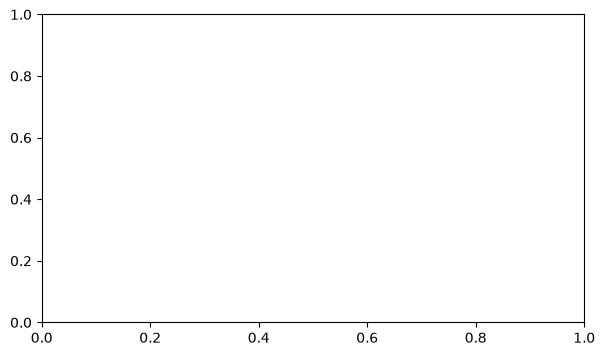

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(abt["age"], bins=range(0, 100, 5), color=BLUE, edgecolor="white")
ax.set_title("Age distribution of patients (n=500)"); ax.set_xlabel("Age (years)"); ax.set_ylabel("Number of patients")
show()

**Figure 1 - Age distribution.** Ages are spread almost evenly from 0 to 95 (median 50, mean 49.2), with no dominant age. Children (0-17) are 101 of 500 patients and 65+ patients 174: the hospital serves all life stages, so age should be used as a segmentation variable rather than dropped.

<a id="3_1_2"></a>

## <font color='turquoise'>  3.1.2 Gender Distribution

KeyError: 'gender'

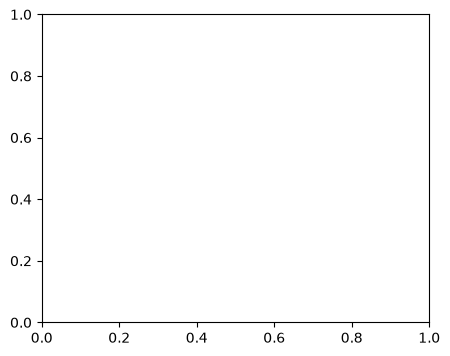

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
gc = abt["gender"].value_counts()
ax.bar(gc.index, gc.values, color=BLUE)
for i, v in enumerate(gc.values):
    ax.text(i, v + 3, f"{v} ({v/5:.0f}%)", ha="center")
ax.set_title("Patients by gender"); ax.set_xlabel("Gender"); ax.set_ylabel("Number of patients"); ax.set_ylim(0, gc.max() * 1.15)
show()

**Figure 2 - Gender.** The three gender categories are almost balanced (Female 169, Male 160, Other 171 patients). The large 'Other' share (~1/3) is unusual for real hospital data and should be confirmed with the data owner, but it is internally consistent after cleaning.

<a id="3_1_3"></a>

## <font color='turquoise'> 3.1.3 Income Distribution

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(abt["annual_income"], bins=30, color=BLUE, edgecolor="white")
axes[0].set_title("Annual income - all patients"); axes[0].set_xlabel("Annual income (GBP)"); axes[0].set_ylabel("Number of patients")
order = abt.groupby("profession")["annual_income"].median().sort_values().index
sns.boxplot(data=abt, x="annual_income", y="profession", order=order, color="#bcd3ee", medianprops=dict(color=RED), ax=axes[1])
axes[1].set_title("Annual income by profession"); axes[1].set_xlabel("Annual income (GBP)"); axes[1].set_ylabel("Profession")
show()

**Figure 3 - Income distribution.** Median patient income is £43,458; 110 patients (22%) have zero income (children and students). Among adults, income is nearly identical across professions (~£43-46k), so profession carries little information about income, while student/non-student carries a lot.

<a id="3_2"></a>

## <font color='turquoise'> 3.2 Department and Service Usage

[Back to TOC](#toc)

<a id="3_2_1"></a>

## <font color='turquoise'> 3.2.1 Consultations by Department

In [ ]:
dv = df["Department"].astype(str).value_counts()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(dv.index[::-1], dv.values[::-1], color=BLUE)
for i, v in enumerate(dv.values[::-1]):
    ax.text(v + 10, i, str(v), va="center", fontsize=9)
ax.set_title("Consultations per department, Jan-Jun 2024"); ax.set_xlabel("Number of visits"); ax.set_ylabel("Department")
ax.set_xlim(0, dv.max() * 1.1)
show()

**Figure 4 - Visits per department.** Psychiatry (1,359) and General Practice (1,331) are the busiest departments and together take 27% of all consultations - about twice the volume of any other department. Orthopedics is the quietest (593).

<a id="3_2_2"></a>

## <font color='turquoise'> 3.2.2 Consultations Over Time

In [ ]:
mt = df.groupby("Month").size()
top4 = dv.index[:4]
pm = df.groupby(["Month", "Department"], observed=True).size().unstack()
pm.columns = pm.columns.astype(str)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(mt.index, mt.values, marker="o", color=BLUE, lw=2)
axes[0].set_ylim(0, mt.max() * 1.2)
axes[0].set_title("Total consultations per month"); axes[0].set_xlabel("Month (2024)"); axes[0].set_ylabel("Number of visits")
for c, dep in zip(CAT, top4):
    axes[1].plot(pm.index, pm[dep], marker="o", lw=2, color=c, label=dep)
axes[1].set_title("Monthly visits, four busiest departments"); axes[1].set_xlabel("Month (2024)"); axes[1].set_ylabel("Number of visits")
axes[1].legend(frameon=False, fontsize=8)
for a in axes:
    a.set_xticks(mt.index); a.set_xticklabels([m.strftime("%b") for m in mt.index])
show()

**Figure 5 - Demand over time.** Total demand is flat: 1,728 visits in January, 1,616 in June, with Feb the lowest simply because it is the shortest month (daily rate is ~53-57 visits in every month). Individual departments fluctuate (e.g. Psychiatry falls from 254 in Jan to 197 in Jun) but there is no consistent trend.

In [ ]:
# heat map department x month (colour = share of the department's visits, cell = visits)
hm = pm.T
hm.columns = [m.strftime("%b") for m in hm.columns]
hm_sh = hm.div(hm.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(hm_sh, annot=hm, fmt="d", cmap="Blues", vmin=10, vmax=24, cbar_kws={"label": "% of department's visits"}, ax=ax)
ax.grid(False); ax.set_title("Visits by department and month (cell = visits)"); ax.set_xlabel("Month (2024)"); ax.set_ylabel("Department")
show()

**Figure 6 - Department × month.** The heat map shows no systematic seasonality by department: counts per cell stay within ~75-255. The visible peaks (Psychiatry in Jan, General Practice in Mar/May) are modest and should be re-checked with a longer time series.

<a id="3_2_3"></a>
## <font color='turquoise'>  3.2.3 Department Usage by Gender or Age Group

In [ ]:
# department by gender (share of the department's visits)
dg = pd.crosstab(df["Department"].astype(str), df["Gender"].astype(str), normalize="index") * 100
dg = dg.loc[dv.index]
fig, ax = plt.subplots(figsize=(9, 4.6))
bottom = np.zeros(len(dg))
x = np.arange(len(dg))
for c, gname in zip([BLUE, ORANGE, TEAL], ["Female", "Male", "Other"]):
    ax.bar(x, dg[gname].values, bottom=bottom, color=c, label=gname, edgecolor="white")
    bottom += dg[gname].values
ax.set_xticks(x); ax.set_xticklabels(dg.index, rotation=40, ha="right")
ax.set_title("Gender mix of each department's visits"); ax.set_xlabel("Department"); ax.set_ylabel("% of visits")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.4))
show()
p_dept_gender = perm_chi2_p(df["Department"].astype(str), df["Gender"].astype(str))
print(f"Permutation chi-square p-value, department vs gender: {p_dept_gender:.2f}")

**Figure 7 - Department by gender.** Every department has a roughly one-third mix of each gender (Female share 29-36%). The differences are small and not statistically significant (permutation chi-square test, p = 0.23), so gender does not discriminate department use in this data.

In [ ]:
# department by age group (share of the age group's visits)
da = pd.crosstab(df["age_group"].astype(str), df["Department"].astype(str), normalize="index") * 100
da = da.loc[AGE_LAB, dv.index]
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(da, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of visits"}, ax=ax)
ax.grid(False); ax.set_title("Department mix by age group (% of the group's visits)"); ax.set_xlabel("Department"); ax.set_ylabel("Age group (years)")
plt.xticks(rotation=40, ha="right")
show()
p_dept_age = perm_chi2_p(df["age_group"].astype(str), df["Department"].astype(str))
print(f"Permutation chi-square p-value, department vs age group: {p_dept_age:.2f}")

**Figure 8 - Department by age group.** Department mix is similar across age groups (permutation chi-square test, p = 0.20). Descriptive hints, to be treated as hypotheses only: Orthopedics is lowest for 50-64 (4.7% vs ~6.5% overall), Emergency is lowest for 80+ (5.3%), Pulmonology is highest for 80+ (7.7%).

<a id="3_3"></a>

## <font color='turquoise'> 3.3 Patient Satisfaction

[Back to TOC](#toc)

<a id="3_3_1"></a>

## <font color='turquoise'> 3.3.1 Satisfaction by Department

In [ ]:
sat = df.dropna(subset=["Satisfaction Level"])
sd = sat.groupby("Department", observed=True)["Satisfaction Level"].agg(["mean", "std", "count"])
sd.index = sd.index.astype(str)
sd["ci"] = 1.96 * sd["std"] / np.sqrt(sd["count"])
sd = sd.sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.errorbar(sd["mean"], range(len(sd)), xerr=sd["ci"], fmt="o", color=BLUE, ecolor=GREY, capsize=3)
ax.axvline(sat["Satisfaction Level"].mean(), color=RED, ls="--", lw=1, label="Hospital average")
ax.set_yticks(range(len(sd))); ax.set_yticklabels(sd.index)
ax.set_title("Average satisfaction by department (95% CI)"); ax.set_xlabel("Mean satisfaction (1-5)"); ax.set_ylabel("Department")
ax.legend(frameon=False)
show()
p_sat_dept = perm_anova_p(sat["Department"].astype(str), sat["Satisfaction Level"])
print(f"Permutation ANOVA p-value, satisfaction by department: {p_sat_dept:.2f}")

**Figure 9 - Satisfaction by department.** Average satisfaction on the valid 1-5 scale is 2.99. General Practice is lowest (2.85) and Gastroenterology highest (3.09), but the confidence intervals overlap and the overall test is not significant (permutation ANOVA, p = 0.08). General Practice is the best candidate to monitor because it is also the second-busiest department.

<a id="3_3_2"></a>

## <font color='turquoise'> 3.3.2 Satisfaction by Patient Segment

In [ ]:
segs = [("age_group", "Age group", AGE_LAB), ("Gender", "Gender", ["Female", "Male", "Other"]),
        ("Insurance Provider", "Insurance provider", ["None", "Provider A", "Provider B", "Provider C", "Provider D"]),
        ("City of Residence", "City", None)]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
p_sat_seg = {}
for ax, (col, lab, order) in zip(axes, segs):
    a = sat.groupby(col, observed=True)["Satisfaction Level"].agg(["mean", "std", "count"])
    a.index = a.index.astype(str)
    a["ci"] = 1.96 * a["std"] / np.sqrt(a["count"])
    a = a.loc[order] if order is not None else a.sort_values("mean")
    ax.errorbar(range(len(a)), a["mean"], yerr=a["ci"], fmt="o", color=BLUE, ecolor=GREY, capsize=3, ms=7)
    ax.set_xticks(range(len(a)))
    ax.set_xticklabels([i.replace("Provider ", "") if col == "Insurance Provider" else i for i in a.index], rotation=45, ha="right")
    ax.set_xlabel(lab); ax.set_ylim(2.5, 3.5); ax.set_xlim(-.5, len(a) - .5)
    ax.axhline(sat["Satisfaction Level"].mean(), color=RED, ls="--", lw=1)
    p_sat_seg[lab] = perm_anova_p(sat[col].astype(str), sat["Satisfaction Level"])
axes[0].set_ylabel("Mean satisfaction (1-5)")
fig.suptitle("Average satisfaction by patient segment (95% CI; dashed = hospital average)", fontweight="bold")
show()
print("Permutation ANOVA p-values, satisfaction by segment:", {k: round(v, 2) for k, v in p_sat_seg.items()})

**Figure 10 - Satisfaction by patient segment.** No patient segment stands out: age group (p = 0.54), gender (p = 0.64), insurance provider (p = 0.93) and city (p = 0.95) all sit within about ±0.1 of the hospital average of 2.99. Satisfaction is therefore not explained by the demographic variables in the ABT.

<a id="3_4"></a>

## <font color='turquoise'> 3.4 Additional Visualizations

[Back to TOC](#toc)


In [ ]:
# satisfaction distribution + relation with consultation length
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
vc = sat["Satisfaction Level"].value_counts(normalize=True).sort_index() * 100
axes[0].bar(vc.index.astype(int), vc.values, color=BLUE)
axes[0].set_title("Distribution of valid ratings"); axes[0].set_xlabel("Satisfaction (1-5)"); axes[0].set_ylabel("% of rated visits")
dur_bins = pd.cut(sat["Consultation Duration"], [14, 30, 45, 60, 75, 90, 105, 120])
db = sat.groupby(dur_bins, observed=True)["Satisfaction Level"].mean()
axes[1].plot(range(len(db)), db.values, marker="o", color=BLUE, lw=2)
axes[1].set_xticks(range(len(db))); axes[1].set_xticklabels([f"{int(i.left)+1}-{int(i.right)}" for i in db.index], rotation=30)
axes[1].set_ylim(1, 5); axes[1].set_title("Satisfaction vs consultation length"); axes[1].set_xlabel("Duration (min)"); axes[1].set_ylabel("Mean satisfaction (1-5)")
show()
print(f"Correlation duration vs rating: {sat['Consultation Duration'].corr(sat['Satisfaction Level']):.2f} | "
      f"visits with invalid rating: {df['flag_rating_invalid'].mean():.1%}")

**Figure 11 - Ratings and consultation length.** Ratings are spread evenly over 1-5 and are unrelated to consultation length (correlation 0.00). Note that 7.2% of visits carried an invalid rating of 6, all but 4 of them in General Practice and ENT.

In [ ]:
# financial: who pays - insurer vs patient
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
fin = df.groupby("Insurance Provider", observed=True)[["Consultation Price", "Insurance Coverage", "out_of_pocket"]].sum()
fin.index = fin.index.astype(str)
fin = fin.loc[["None", "Provider C", "Provider A", "Provider B", "Provider D"]]
cov_pct = fin["Insurance Coverage"] / fin["Consultation Price"] * 100
axes[0].bar(range(5), cov_pct.values, color=BLUE)
axes[0].bar(range(5), 100 - cov_pct.values, bottom=cov_pct.values, color=ORANGE)
axes[0].set_xticks(range(5)); axes[0].set_xticklabels(fin.index, rotation=20)
for i, v in enumerate(cov_pct.values):
    axes[0].text(i, v / 2 if v > 15 else v + 4, f"{v:.0f}%", ha="center", color="white" if v > 15 else "black")
axes[0].set_title("Who pays: insurer (blue) vs patient (orange)"); axes[0].set_xlabel("Insurance provider"); axes[0].set_ylabel("% of consultation price")
fd = df.groupby("Department", observed=True)[["Consultation Price", "Insurance Coverage", "out_of_pocket"]].sum()
fd.index = fd.index.astype(str)
fd["avg_oop"] = df.groupby("Department", observed=True)["out_of_pocket"].mean().values
fd["avg_cov"] = df.groupby("Department", observed=True)["Insurance Coverage"].mean().values
fd = fd.sort_values("avg_oop")
axes[1].barh(fd.index, fd["avg_cov"], color=BLUE, label="Insurer pays")
axes[1].barh(fd.index, fd["avg_oop"], left=fd["avg_cov"], color=ORANGE, label="Patient pays")
axes[1].set_title("Average price per visit and who pays it"); axes[1].set_xlabel("GBP per consultation"); axes[1].set_ylabel("Department")
axes[1].legend(frameon=False, loc="lower right")
show()


**Figure 12 - Insurance coverage and out-of-pocket cost.** Insurers cover 69.9% of the £1,651,138 billed (patients pay £496,679, 30.1%). Coverage follows a fixed rule per provider (C 70%, A 80%, B 90%, D 100%, none 0%). The 90 uninsured patients (18%) pay 60% of all out-of-pocket money (≈£164 per visit). Emergency (≈£300/visit) is the costliest department; ENT and General Practice (≈£75) the cheapest.

In [ ]:
# visits per patient + recency
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(abt["n_visits"], bins=range(8, 42, 2), color=BLUE, edgecolor="white")
axes[0].set_title("Visits per patient (6 months)"); axes[0].set_xlabel("Number of visits"); axes[0].set_ylabel("Number of patients")
axes[1].hist(abt["days_since_last_visit"], bins=range(0, 40, 2), color=BLUE, edgecolor="white")
axes[1].set_title("Recency: days since last visit (at 1 Jul 2024)"); axes[1].set_xlabel("Days since last visit"); axes[1].set_ylabel("Number of patients")
show()

**Figure 13 - Visits per patient and recency.** Patients visit 20 times on average in six months (range 9-39) and the median patient was last seen only 6.5 days before the reference date (max 53). All 500 patients are active, so recency cannot identify churn in this window.

In [ ]:
# visits per patient by age group
fig, ax = plt.subplots(figsize=(7, 4))
vp = abt.groupby("age_group")["n_visits"].agg(["mean", "std", "count"]).loc[AGE_LAB]
ax.bar(range(6), vp["mean"], yerr=1.96 * vp["std"] / np.sqrt(vp["count"]), color=BLUE, capsize=3, ecolor=GREY)
ax.set_xticks(range(6)); ax.set_xticklabels(AGE_LAB); ax.set_title("Average visits per patient by age group")
ax.set_xlabel("Age group (years)"); ax.set_ylabel("Mean number of visits")
show()
print(f"ANOVA (permutation) p-value, visits by age group: {perm_anova_p(abt['age_group'], abt['n_visits']):.2f}")

**Figure 14 - Visits by age group.** The number of visits per patient does not depend on age (all groups 18.7-20.7 visits; permutation ANOVA p = 0.13).

In [ ]:
# data-cleaning evidence: raw vs clean price / income / duration
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
pairs = [("Consultation Price", "Consultation price", "GBP (log scale)", "log"),
         ("Approximate Annual Income", "Annual income", "GBP (symlog scale)", "symlog"),
         ("Consultation Duration", "Consultation duration", "Minutes", None)]
for ax, (c, title, ylab, scale) in zip(axes, pairs):
    sns.boxplot(data=[data[c].dropna().astype(float), df[c].dropna().astype(float)], ax=ax, color="#bcd3ee")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Raw", "Clean"])
    if scale == "log":
        ax.set_yscale("log")
    elif scale == "symlog":
        ax.set_yscale("symlog", linthresh=1000)
    ax.set_title(title); ax.set_ylabel(ylab); ax.set_xlabel("Dataset")
show()

**Figure 15 - Cleaning: before vs after.** Before/after view of the three numeric outliers fixed in cleaning: price (×100 errors up to £40,000), income (×10/×100 errors up to £12M) and duration (up to 600 min). After cleaning, all values lie in plausible ranges (price £50-400, duration 15-120 min).

In [ ]:
# correlation of key ABT features
cols = ["age", "annual_income", "n_visits", "n_distinct_departments", "avg_duration_min", "avg_price",
        "total_out_of_pocket", "coverage_share", "avg_satisfaction", "share_low_ratings", "visits_per_month", "days_since_last_visit"]
cm = abt[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".1f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7}, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.grid(False); ax.set_title("Correlation between key patient features"); ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
show()

**Figure 16 - Correlation of key ABT features.** Strongest relations are mechanical: visits and visits per month (0.97), coverage share vs out-of-pocket (-0.95), average satisfaction vs share of low ratings (-0.86). Age-income (0.63) reflects zero income for children/students. Most behavioural and satisfaction features are nearly uncorrelated, so a predictive model should not expect strong signals.

<a id="3_5"></a>
## <font color='turquoise'>  3.5 Management Questions and Key Insights

[Back to TOC](#toc)

In [ ]:
# Key figures behind the answers below (all computed from the cleaned data)
days = mt.index.days_in_month
print("Q1  Visits per department (share of all visits):")
display(pd.DataFrame({"visits": dv, "share_%": (dv / dv.sum() * 100).round(1)}).T)
print("    Visits per month and per day:")
display(pd.DataFrame({"visits": mt.values, "per_day": (mt.values / days).round(1)}, index=[m.strftime("%b") for m in mt.index]).T)
print("    Change in visits, Jan -> Jun, by department:")
display((pm.loc[pm.index.max()] - pm.loc[pm.index.min()]).sort_values().to_frame("jun_minus_jan").T)

print("Q2  Most used department by age group and gender (share of that group's visits):")
display(pd.DataFrame({"top_department": da.idxmax(axis=1), "share_%": da.max(axis=1).round(1)}).T)
dgx = pd.crosstab(df["Gender"].astype(str), df["Department"].astype(str), normalize="index") * 100   # share of each gender's visits
print("    ... and by gender:")
display(pd.DataFrame({"top_department": dgx.idxmax(axis=1), "share_%": dgx.max(axis=1).round(1)}).T)
print(f"    chi-square p-values - department vs age group: {p_dept_age:.2f} | vs gender: {p_dept_gender:.2f}")

print("Q3  Satisfaction (valid ratings), lowest departments and overall:")
display(sd[["mean", "count"]].round(2).head(4).T)
print(f"    overall {sat['Satisfaction Level'].mean():.2f} | ANOVA by department p = {p_sat_dept:.2f}")
print("    segment tests (p-values):", {k: round(v, 2) for k, v in p_sat_seg.items()})

print("Q4  Who pays the consultation price:")
tot_price, tot_cov = df["Consultation Price"].sum(), df["Insurance Coverage"].sum()
tot_oop = tot_price - tot_cov
n_uninsured = int((abt["has_insurance"] == 0).sum())
oop_uninsured = df.loc[df["Insurance Provider"].astype(str) == "None", "out_of_pocket"].sum() / tot_oop
print(f"    billed £{tot_price:,.0f} | insurers £{tot_cov:,.0f} ({tot_cov / tot_price:.1%}) | patients £{tot_oop:,.0f} ({tot_oop / tot_price:.1%})")
print(f"    uninsured patients: {n_uninsured} ({n_uninsured / 5:.0f}%), they pay {oop_uninsured:.0%} of all out-of-pocket money")
print(f"    average price per visit £{df['Consultation Price'].mean():.0f}, average out-of-pocket £{df['out_of_pocket'].mean():.0f}")

**Answers to management's questions**

1. **Busiest departments and demand from January to June.** Psychiatry (1,359 visits) and General Practice (1,331) are the busiest, together 27% of all consultations and about twice any other department; Orthopedics is the quietest (593). Total demand is flat over the six months (1,728 visits in January, 1,616 in June; ~53-57 visits per day in every month). Departments fluctuate month to month (Psychiatry 254 → 197) but there is no consistent trend or seasonality.
2. **Which patient groups use which departments.** Department mix is very similar across age groups (p = 0.20) and genders (p = 0.23), so no group is tied to a department. The most-used department is General Practice for children (0-17) and for 65+, and Psychiatry for ages 18-64, but always with only ~14% of the group's visits, a negligible lead. Only weak hints exist (Orthopedics lowest for 50-64, Emergency lowest and Pulmonology highest for 80+) and should be treated as hypotheses.
3. **Lowest satisfaction.** Average satisfaction is 2.99/5. General Practice is lowest (2.85) and Gastroenterology highest (3.09), but the differences are not significant (p = 0.08). No patient segment (age, gender, insurer, city) differs from the average either, so satisfaction is not explained by the demographics in the ABT. General Practice deserves monitoring because it is both the lowest-rated and the second-busiest department.
4. **Insurance vs out-of-pocket.** Insurers cover 69.9% of the £1.65M billed; patients pay £496,679 (30.1%). Coverage is a fixed rate per provider (C 70%, A 80%, B 90%, D 100%, none 0%). The 90 uninsured patients (18%) pay about 60% of all out-of-pocket money (≈£164 per visit).

**Suggestions for the next analytics team**

- **Sensible targets:** `avg_satisfaction` / `share_low_ratings` (experience), `n_visits` / `visits_per_month` (utilisation), `total_out_of_pocket` or `oop_to_income_pct` (financial burden) and `top_department` (service demand). Expect weak signals: most behavioural and satisfaction features are almost uncorrelated.
- **Segmentation ideas:** cluster on age group, income, insurance status and utilisation (`n_visits`, `n_distinct_departments`, `share_emergency`); treat uninsured patients as a distinct group because of their financial exposure.
- **Caveats:** all patients were active in the window, so recency cannot define churn; the `Other` gender share (~1/3) should be confirmed; the rating-6 code is concentrated in two departments; four patients have a profession that does not fit their age (`profession_age_odd`); and visits flagged in `flag_same_day_same_dept` may need review. Use the `dq_*` columns to test how sensitive any result is to repaired data.